# Null baseline for perturbation-state prediction

This notebook builds canonical states for ten common perturbations and evaluates a null model that predicts no change from the canonical control state.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

DATA_PATH = "../data/raw/replogle22rpe1.h5ad"

adata = sc.read_h5ad(DATA_PATH)
print(adata)

AnnData object with n_obs × n_vars = 240774 × 8749
    obs: 'perturbation'


## Select ten common perturbations

In [2]:
counts = adata.obs["perturbation"].value_counts().drop("control")
top_perturbations = counts.head(10).index.tolist()

pd.DataFrame({
    "perturbation": top_perturbations,
    "cell_count": counts.loc[top_perturbations].values,
})

,perturbation,cell_count
0,TFAM,3580
1,SLC1A5,1962
2,GFM1,1699
3,MRPL36,1686
4,TARDBP,1675
5,PPP6C,1581
6,MRPL35,1491
7,NBPF12,1159
8,CCDC6,1086
9,GTF3C4,942


## Build canonical perturbation and control states

In [3]:
states = {}

for perturbation in top_perturbations:
    subset = adata[adata.obs["perturbation"] == perturbation]
    states[perturbation] = np.asarray(subset.X.mean(axis=0)).flatten()

state_matrix = pd.DataFrame(states, index=adata.var_names).T

control = adata[adata.obs["perturbation"] == "control"]
control_state = np.asarray(control.X.mean(axis=0)).flatten()

print("Perturbation state matrix shape:", state_matrix.shape)
print("Control state shape:", control_state.shape)

Perturbation state matrix shape: (10, 8749)
Control state shape: (8749,)


## Calculate the observed perturbation effects

Each row is the measured canonical perturbation state minus the canonical control state.

In [4]:
effect_df = state_matrix.subtract(control_state, axis="columns")

print("Effect matrix shape:", effect_df.shape)
effect_df.iloc[:, :10]

Effect matrix shape: (10, 8749)


,NOC2L,PLEKHN1,HES4,ISG15,AGRN,SDF4,B3GALT6,UBE2J2,ACAP3,PUSL1
TFAM,0.024143,-0.003928,0.015241,0.001672,0.007972,0.020714,0.009742,0.012946,-0.001304,0.005515
SLC1A5,-0.006777,0.003697,0.034878,-0.000432,-0.006341,-0.017090,-0.010164,0.010757,0.013372,-0.000749
GFM1,-0.013278,0.007859,-0.003783,-0.007088,0.010739,-0.013584,-0.015580,-0.003625,-0.008740,-0.002236
MRPL36,-0.007193,-0.003986,0.037392,-0.034869,-0.007204,0.006665,-0.017210,-0.008042,-0.007970,-0.000272
TARDBP,0.017289,-0.001842,-0.036525,0.011098,-0.019583,0.079922,-0.015140,-0.038799,-0.010931,-0.023602
PPP6C,-0.004629,-0.009001,-0.121162,0.009488,0.011393,0.057666,0.023393,-0.011639,0.003653,-0.019170
MRPL35,-0.014058,0.004493,-0.007494,-0.013192,-0.018431,-0.009652,-0.006779,0.000831,-0.003132,0.012566
NBPF12,0.000024,-0.004876,-0.038151,0.003444,0.001420,0.004702,0.003434,-0.005665,-0.009582,0.001220
CCDC6,0.006342,-0.013290,0.053179,-0.008797,0.013742,-0.022077,-0.002279,-0.012397,-0.003510,-0.005759
GTF3C4,-0.031143,0.002273,-0.073225,0.013767,-0.013811,0.021130,-0.015731,0.000120,-0.018377,0.000811


## Evaluate the no-change null model

For every perturbation, the null model predicts that the resulting expression state equals the canonical control state.

In [5]:
baseline_results = pd.DataFrame({
    "perturbation": top_perturbations,
    "mse": [
        mean_squared_error(state_matrix.loc[perturbation], control_state)
        for perturbation in top_perturbations
    ],
}).sort_values("mse", ascending=False, ignore_index=True)

baseline_results

,perturbation,mse
0,TARDBP,0.003083
1,PPP6C,0.002367
2,GTF3C4,0.002242
3,TFAM,0.001976
4,CCDC6,0.001018
5,GFM1,0.000880
6,MRPL36,0.000855
7,MRPL35,0.000722
8,NBPF12,0.000504
9,SLC1A5,0.000187


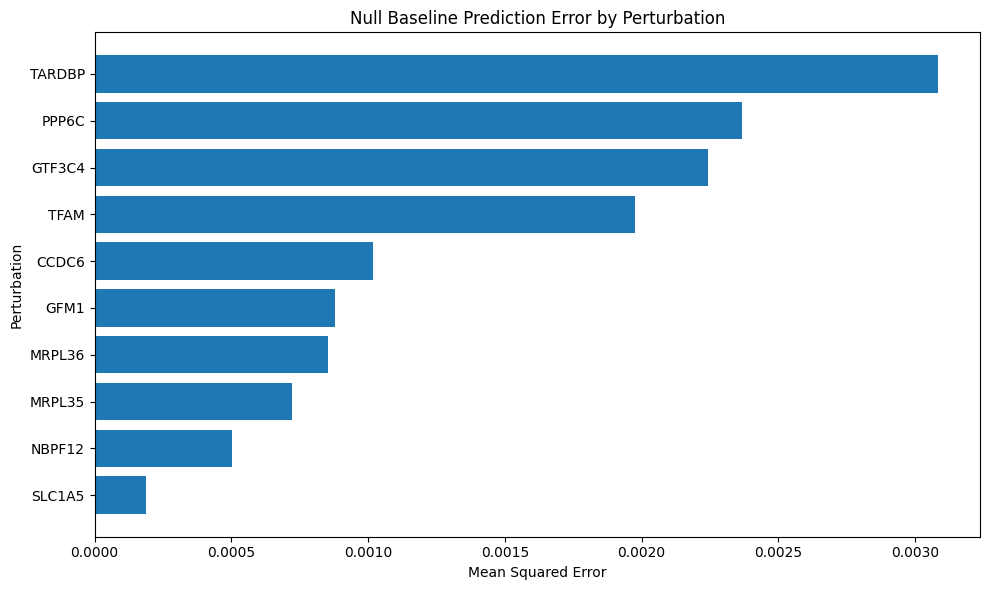

In [6]:
plot_data = baseline_results.sort_values("mse")

plt.figure(figsize=(10, 6))
plt.barh(plot_data["perturbation"], plot_data["mse"])
plt.xlabel("Mean Squared Error")
plt.ylabel("Perturbation")
plt.title("Null Baseline Prediction Error by Perturbation")
plt.tight_layout()
plt.show()